In [1]:
import os, glob, json, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
!pip install xgboost
import xgboost as xgb
!pip install optuna
import optuna

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid")

SEED = 42
N_TRIALS = 100         # Optuna trials
N_FINAL_SEEDS = 5      # seeds averaged in the final model
np.random.seed(SEED)
print("xgboost", xgb.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 21.8 MB/s eta 0:00:00
xgboost 3.4.1


In [2]:
train=pd.read_csv("/content/train.csv")
test=pd.read_csv("/content/test.csv")
sample_sub=pd.read_csv("/content/submission.csv")

In [3]:
print("train", train.shape, "| test", test.shape, "| sample submission", sample_sub.shape)
print("missing  train/test:", train.isna().sum().sum(), "/", test.isna().sum().sum())
print("duplicate rows in train:", train.duplicated().sum())
print("test ids all in sample submission:", set(test.id) == set(sample_sub.id))
train.head()

train (18076, 12) | test (4520, 11) | sample submission (4520, 2)
missing  train/test: 0 / 0
duplicate rows in train: 0
test ids all in sample submission: True


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
0,2856,Southwest,WN 3596,San Jose,Early_Morning,zero,Morning,Los Angeles,Economy,1.33,5,315
1,21812,Southwest,WN 1307,San Jose,Evening,zero,Evening,San Diego,Economy,1.58,40,149
2,476,United,UA 1763,San Diego,Afternoon,zero,Afternoon,San Francisco,Economy,1.77,2,129
3,21802,Southwest,WN 367,San Jose,Morning,zero,Morning,San Diego,Economy,1.58,40,94
4,5099,United,UA 2117,San Diego,Afternoon,zero,Evening,San Francisco,Economy,1.70,9,146


In [4]:
print(train.describe().T.round(2))
cat_cols_raw = ["airline", "source_city", "departure_time", "stops", "arrival_time", "destination_city", "flight_class"]
print()
for c in cat_cols_raw:
    unseen = set(test[c]) - set(train[c])
    print(f"{c:17s} train={train[c].nunique()} test={test[c].nunique()} unseen_in_test={unseen or '-'}")
print("flight numbers:", train.flight.nunique(), "| in test but never in train:", len(set(test.flight) - set(train.flight)))

             count      mean      std   min      25%       50%      75%  \
id         18076.0  11308.63  6526.34  0.00  5668.75  11329.50  16949.5   
duration   18076.0      2.75     2.95  0.87     1.47      1.63      2.0   
days_left  18076.0     20.52    12.09  1.00    10.00     20.00     31.0   
price      18076.0    280.26   221.97  0.00   157.00    234.00    336.0   

                max  
id         22595.00  
duration      28.65  
days_left     44.00  
price       8996.00  

airline           train=7 test=6 unseen_in_test=-
source_city       train=5 test=5 unseen_in_test=-
departure_time    train=6 test=6 unseen_in_test=-
stops             train=3 test=3 unseen_in_test=-
arrival_time      train=6 test=6 unseen_in_test=-
destination_city  train=5 test=5 unseen_in_test=-
flight_class      train=2 test=2 unseen_in_test=-
flight numbers: 1123 | in test but never in train: 33


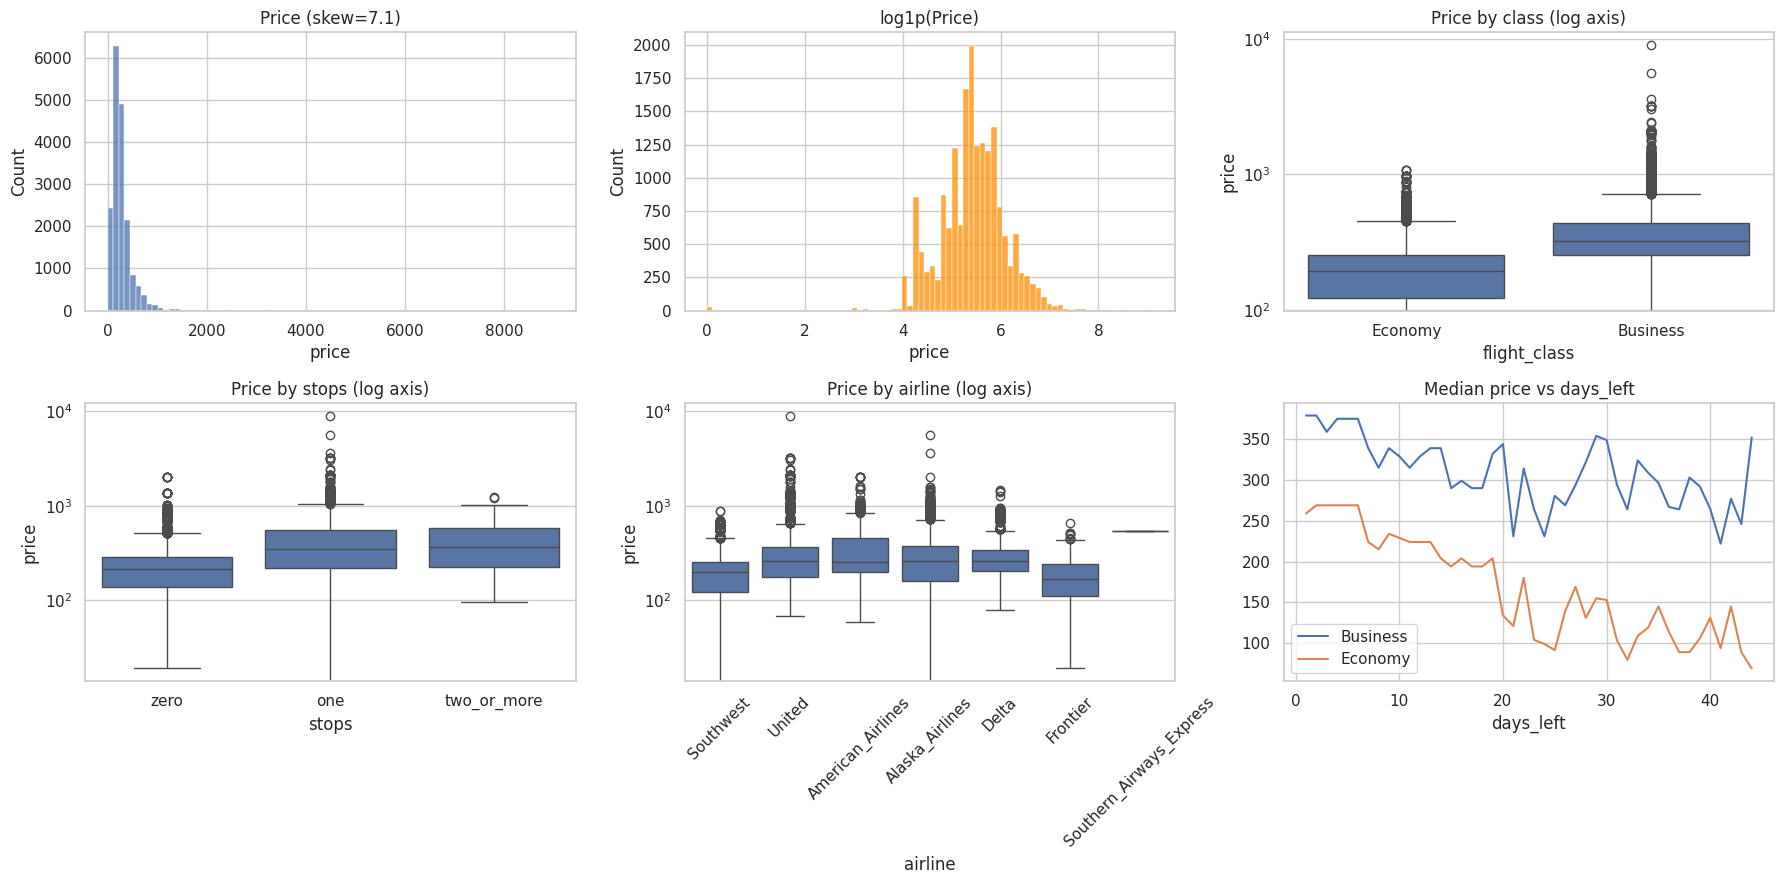

In [5]:
fig, ax = plt.subplots(2, 3, figsize=(18, 9))
sns.histplot(train.price, bins=80, ax=ax[0, 0]); ax[0, 0].set_title(f"Price (skew={train.price.skew():.1f})")
sns.histplot(np.log1p(train.price), bins=80, ax=ax[0, 1], color="darkorange"); ax[0, 1].set_title("log1p(Price)")
sns.boxplot(data=train, x="flight_class", y="price", ax=ax[0, 2]); ax[0, 2].set_yscale("log"); ax[0, 2].set_title("Price by class (log axis)")
sns.boxplot(data=train, x="stops", y="price", order=["zero", "one", "two_or_more"], ax=ax[1, 0]); ax[1, 0].set_yscale("log"); ax[1, 0].set_title("Price by stops (log axis)")
sns.boxplot(data=train, x="airline", y="price", ax=ax[1, 1]); ax[1, 1].set_yscale("log"); ax[1, 1].tick_params(axis="x", rotation=45); ax[1, 1].set_title("Price by airline (log axis)")
for cls, g in train.groupby("flight_class"):
    ax[1, 2].plot(g.groupby("days_left").price.median(), label=cls)
ax[1, 2].set_title("Median price vs days_left"); ax[1, 2].set_xlabel("days_left"); ax[1, 2].legend()
plt.tight_layout(); plt.show()

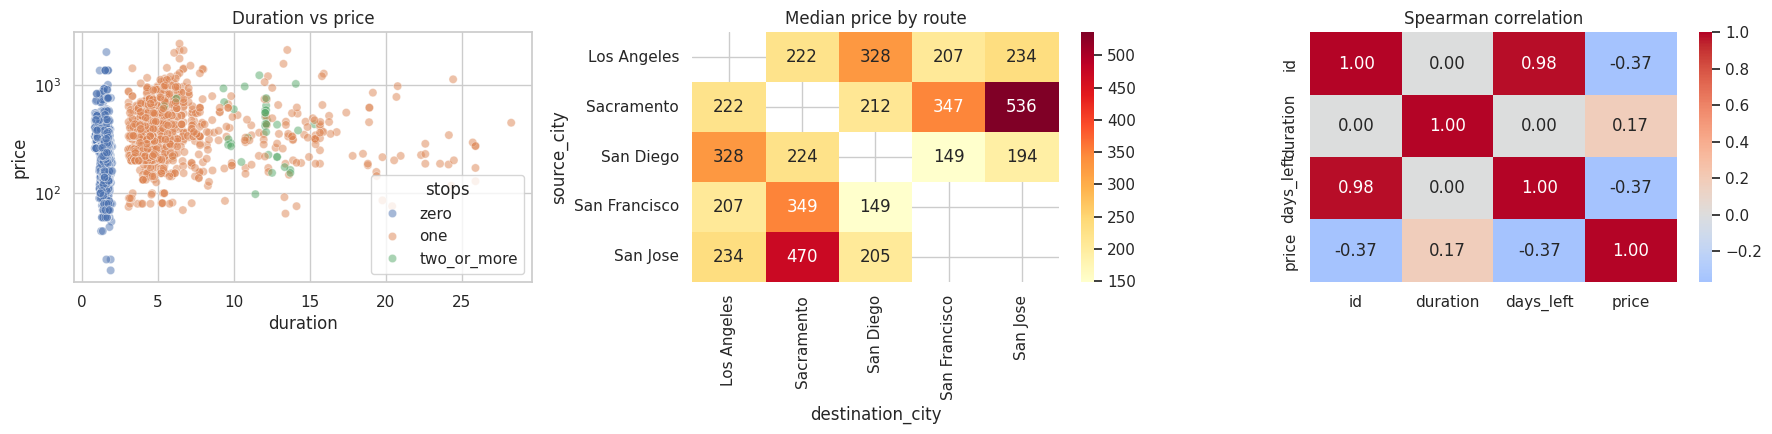

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
sns.scatterplot(data=train.sample(4000, random_state=0), x="duration", y="price", hue="stops", alpha=.5, ax=ax[0]); ax[0].set_yscale("log"); ax[0].set_title("Duration vs price")
piv = train.assign(route=train.source_city + "→" + train.destination_city).groupby(["source_city", "destination_city"]).price.median().unstack()
sns.heatmap(piv, annot=True, fmt=".0f", cmap="YlOrRd", ax=ax[1]); ax[1].set_title("Median price by route")
num = train[["id", "duration", "days_left", "price"]]
sns.heatmap(num.corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[2]); ax[2].set_title("Spearman correlation")
plt.tight_layout(); plt.show()

In [7]:
print("price == 0 rows:", (train.price == 0).sum(), "| price > 2000 rows:", (train.price > 2000).sum())
print(train.loc[train.price == 0, ["airline", "stops", "flight_class"]].value_counts().head(), "\n")
print(train.loc[train.price > 2000, ["airline", "stops", "flight_class"]].value_counts().head())

price == 0 rows: 25 | price > 2000 rows: 31
airline          stops  flight_class
Southwest        one    Economy         23
Alaska_Airlines  one    Business         1
                        Economy          1
Name: count, dtype: int64 

airline            stops  flight_class
United             one    Business        23
American_Airlines  zero   Business         6
Alaska_Airlines    one    Business         2
Name: count, dtype: int64


In [8]:
TIME_ORDER = {"Early_Morning": 0, "Morning": 1, "Afternoon": 2, "Evening": 3, "Night": 4, "Late_Night": 5}
STOPS_ORDER = {"zero": 0, "one": 1, "two_or_more": 2}

full = pd.concat([train.assign(_is_train=1), test.assign(_is_train=0)], ignore_index=True)

def make_features(d: pd.DataFrame, flight_counts: pd.Series) -> pd.DataFrame:
    f = pd.DataFrame(index=d.index)
    f["id"] = d["id"]                                           # kept only for the ablation, not used by default
    f["duration"] = d["duration"]
    f["days_left"] = d["days_left"]
    f["stops_n"] = d["stops"].map(STOPS_ORDER)
    f["dep_ord"] = d["departure_time"].map(TIME_ORDER)
    f["arr_ord"] = d["arrival_time"].map(TIME_ORDER)
    f["is_business"] = (d["flight_class"] == "Business").astype(int)
    f["flight_num"] = d["flight"].str.split().str[1].astype(int)
    f["overnight"] = (f["arr_ord"] < f["dep_ord"]).astype(int)
    f["dur_per_leg"] = d["duration"] / (f["stops_n"] + 1)
    f["last_week"] = (d["days_left"] <= 7).astype(int)
    f["last_3days"] = (d["days_left"] <= 3).astype(int)
    f["flight_freq"] = d["flight"].map(flight_counts).astype(int)  # unsupervised popularity of the flight number
    # categoricals (native XGBoost categorical support)
    f["airline"] = d["airline"]
    f["source_city"] = d["source_city"]
    f["destination_city"] = d["destination_city"]
    f["route"] = d["source_city"] + ">" + d["destination_city"]
    f["route_class"] = f["route"] + "|" + d["flight_class"]
    f["route_stops"] = f["route"] + "|" + d["stops"]
    # key for target encoding (not a model feature itself)
    f["flight_key"] = d["flight"] + "|" + d["flight_class"]
    return f

flight_counts = full["flight"].value_counts()
F = make_features(full, flight_counts)
CAT_FEATS = ["airline", "source_city", "destination_city", "route", "route_class", "route_stops"]
for c in CAT_FEATS:
    F[c] = F[c].astype("category")   # same category universe for train and test

F_train = F[full._is_train == 1].reset_index(drop=True)
F_test = F[full._is_train == 0].reset_index(drop=True)
y = train["price"].values.astype(float)
print(F_train.shape, F_test.shape)
F_train.head(3)

(18076, 20) (4520, 20)


,id,duration,days_left,stops_n,dep_ord,arr_ord,is_business,flight_num,overnight,dur_per_leg,last_week,last_3days,flight_freq,airline,source_city,destination_city,route,route_class,route_stops,flight_key
0,2856,1.33,5,0,0,1,0,3596,0,1.33,1,0,8,Southwest,San Jose,Los Angeles,San Jose>Los Angeles,San Jose>Los Angeles|Economy,San Jose>Los Angeles|zero,WN 3596|Economy
1,21812,1.58,40,0,3,3,0,1307,0,1.58,0,0,25,Southwest,San Jose,San Diego,San Jose>San Diego,San Jose>San Diego|Economy,San Jose>San Diego|zero,WN 1307|Economy
2,476,1.77,2,0,2,2,0,1763,0,1.77,1,1,82,United,San Diego,San Francisco,San Diego>San Francisco,San Diego>San Francisco|Economy,San Diego>San Francisco|zero,UA 1763|Economy


In [9]:
def te_fit_apply(tr, y_tr_log, others, key="flight_key", n_splits=5, smooth=10, seed=SEED):
    """Smoothed target encoding of `key` using log1p(price).
    - train rows: out-of-fold encoding (a row never sees its own target)
    - other frames (val / test): encoding from the full training part."""
    prior = y_tr_log.mean()
    def stats(k, y_):
        g = pd.DataFrame({"k": k.values, "y": y_}).groupby("k").y.agg(["sum", "count"])
        return g
    def enc(k, g):
        s = k.map(g["sum"]).fillna(0).values; n = k.map(g["count"]).fillna(0).values
        return (s + smooth * prior) / (n + smooth)
    te_tr = np.zeros(len(tr))
    for a, b in KFold(n_splits, shuffle=True, random_state=seed).split(tr):
        te_tr[b] = enc(tr[key].iloc[b], stats(tr[key].iloc[a], y_tr_log[a]))
    g_full = stats(tr[key], y_tr_log)
    tr = tr.assign(te_flight=te_tr)
    others = [o.assign(te_flight=enc(o[key], g_full)) for o in others]
    return tr, others

In [10]:
bins = pd.qcut(y, 10, labels=False, duplicates="drop")  # stratify on price decile
idx_dev, idx_hold = train_test_split(np.arange(len(y)), test_size=0.2, random_state=SEED, stratify=bins)
dev_X, dev_y, dev_bins = F_train.iloc[idx_dev].reset_index(drop=True), y[idx_dev], bins[idx_dev]
hold_X, hold_y = F_train.iloc[idx_hold].reset_index(drop=True), y[idx_hold]
print("dev", dev_X.shape, "| hold-out", hold_X.shape)

# Pre-compute CV folds once (target encoding depends only on data, not on XGB params) -> fast tuning
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
FOLDS = []
for a, b in skf.split(dev_X, dev_bins):
    Xa, (Xb,) = te_fit_apply(dev_X.iloc[a].reset_index(drop=True), np.log1p(dev_y[a]), [dev_X.iloc[b].reset_index(drop=True)])
    FOLDS.append((Xa, dev_y[a], Xb, dev_y[b]))
print("cached", len(FOLDS), "folds")

dev (14460, 20) | hold-out (3616, 20)
cached 5 folds


In [11]:

ID_FREE = [c for c in FOLDS[0][0].columns if c not in ("id", "flight_key")]   # default feature pool

BASE_PARAMS = dict(learning_rate=0.05, max_depth=6, min_child_weight=1, subsample=0.8, colsample_bytree=0.8,
                   reg_lambda=1.0, reg_alpha=0.0, gamma=0.0)

def cv_score(cols, params, target="log", max_rounds=1500, es=50, seed=SEED):
    """5-fold CV on dev. Returns mean/std RMSE on the *raw price scale*, mean best iteration, OOF preds."""
    scores, iters, oof = [], [], []
    for Xa, ya, Xb, yb in FOLDS:
        ta, tb = (np.log1p(ya), np.log1p(yb)) if target == "log" else (ya, yb)
        m = xgb.XGBRegressor(**params, n_estimators=max_rounds, early_stopping_rounds=es, tree_method="hist",
                             enable_categorical=True, random_state=seed, n_jobs=-1, verbosity=0)
        m.fit(Xa[cols], ta, eval_set=[(Xb[cols], tb)], verbose=False)
        p = m.predict(Xb[cols]); p = np.expm1(p) if target == "log" else p
        p = np.clip(p, 0, None)
        scores.append(rmse(yb, p)); iters.append(m.best_iteration + 1); oof.append(p)
    return np.mean(scores), np.std(scores), int(np.mean(iters)), oof

In [12]:
def rmse(a, b): return float(np.sqrt(mean_squared_error(a, b)))
ID_FREE = [c for c in FOLDS[0][0].columns if c not in ("id", "flight_key")]   # default feature pool
BASE_PARAMS = dict(learning_rate=0.05, max_depth=6, min_child_weight=1, subsample=0.8, colsample_bytree=0.8,
                   reg_lambda=1.0, reg_alpha=0.0, gamma=0.0)
HUBER_SLOPE = 300.0
Y_DEV_FOLDS = [f[3] for f in FOLDS]
Y_OOF = np.concatenate(Y_DEV_FOLDS)
MASK = Y_OOF < 4000      # low-noise comparison set: ignores the 2-3 absurd prices (e.g. 8996) that no model can predict

def cv_score(cols, params, mode="huber", max_rounds=1500, es=50, seed=SEED, fixed_rounds=None):
    """5-fold CV on dev. Returns dict with mean fold R2 (the real metric), pooled R2 on prices<4000 (low-noise proxy), best rounds, OOF preds."""
    oof, iters = [], []
    for Xa, ya, Xb, yb in FOLDS:
        ta, tb = (np.log1p(ya), np.log1p(yb)) if mode == "log" else (ya, yb)
        extra = dict(objective="reg:pseudohubererror", huber_slope=HUBER_SLOPE) if mode == "huber" else {}
        extra.update({k: v for k, v in params.items() if k in ("huber_slope",)})
        p2 = {k: v for k, v in params.items() if k != "huber_slope"}
        m = xgb.XGBRegressor(**p2, **extra, n_estimators=fixed_rounds or max_rounds, early_stopping_rounds=None if fixed_rounds else es,
                             tree_method="hist", enable_categorical=True, random_state=seed, n_jobs=-1, verbosity=0)
        if fixed_rounds: m.fit(Xa[cols], ta, verbose=False)
        else: m.fit(Xa[cols], ta, eval_set=[(Xb[cols], tb)], verbose=False)
        p = m.predict(Xb[cols]); p = np.expm1(p) if mode == "log" else p
        oof.append(np.clip(p, 0, None)); iters.append(fixed_rounds or m.best_iteration + 1)
    P = np.concatenate(oof)
    return dict(r2=float(np.mean([r2_score(a, b) for a, b in zip(Y_DEV_FOLDS, oof)])), r2_std=float(np.std([r2_score(a, b) for a, b in zip(Y_DEV_FOLDS, oof)])),
                r2_proxy=float(r2_score(Y_OOF[MASK], P[MASK])), rounds=int(np.mean(iters)), oof=oof)

In [13]:
t0 = time.time(); res = {}
for mode in ["raw", "log", "huber"]:
    r = cv_score(ID_FREE, BASE_PARAMS, mode=mode); res[mode] = r
    print(f"{mode:5s}  CV R2 = {r['r2']:.4f} ± {r['r2_std']:.3f}   | R2 on prices<4000 = {r['r2_proxy']:.4f}   (avg rounds {r['rounds']})")
MODE = max(res, key=lambda k: res[k]["r2"])
print(f"\n-> chosen loss: {MODE}   ({time.time()-t0:.0f}s)")
print("Note: fold-to-fold R2 varies by ±0.08 because a few extreme prices land in different folds – compare models on the SAME folds, as here.")

raw    CV R2 = 0.6806 ± 0.090   | R2 on prices<4000 = 0.7376   (avg rounds 176)
log    CV R2 = 0.6967 ± 0.091   | R2 on prices<4000 = 0.7546   (avg rounds 459)
huber  CV R2 = 0.7081 ± 0.089   | R2 on prices<4000 = 0.7679   (avg rounds 236)

-> chosen loss: huber   (38s)
Note: fold-to-fold R2 varies by ±0.08 because a few extreme prices land in different folds – compare models on the SAME folds, as here.


In [14]:
r_id = cv_score(ID_FREE + ["id"], BASE_PARAMS, mode=MODE)
print(f"without id: R2 {res[MODE]['r2']:.4f}   |   with id: R2 {r_id['r2']:.4f}")

without id: R2 0.7081   |   with id: R2 0.7042


dropped by correlation filter: none


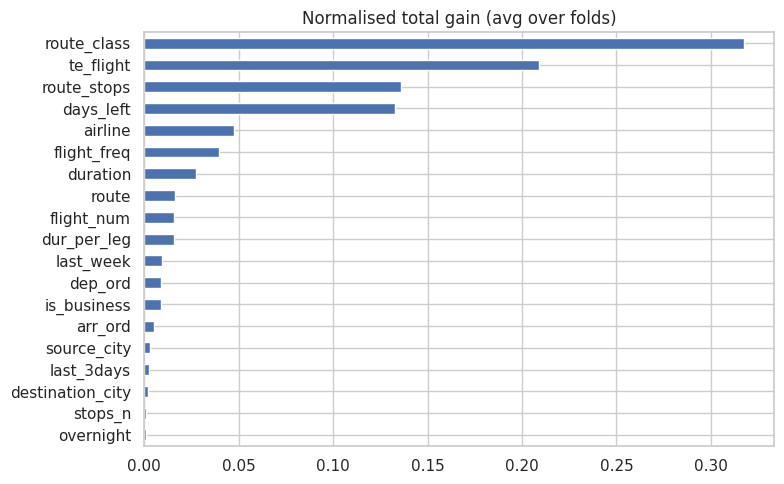

In [15]:
Xall = FOLDS[0][0]
numeric = [c for c in ID_FREE if c not in CAT_FEATS]
corr = Xall[numeric].corr().abs()
drop_corr = set()
for i, a in enumerate(numeric):
    for b in numeric[i + 1:]:
        if corr.loc[a, b] > 0.97 and b not in drop_corr and a not in drop_corr: drop_corr.add(b)
print("dropped by correlation filter:", drop_corr or "none")
pool = [c for c in ID_FREE if c not in drop_corr]

gain = pd.Series(0.0, index=pool)
for Xa, ya, Xb, yb in FOLDS:
    kw = dict(objective="reg:pseudohubererror", huber_slope=HUBER_SLOPE) if MODE == "huber" else {}
    ta = np.log1p(ya) if MODE == "log" else ya
    m = xgb.XGBRegressor(**BASE_PARAMS, **kw, n_estimators=400, tree_method="hist", enable_categorical=True,
                         random_state=SEED, n_jobs=-1, verbosity=0).fit(Xa[pool], ta)
    gain += pd.Series(m.get_booster().get_score(importance_type="total_gain")).reindex(pool).fillna(0)
gain = (gain / gain.sum()).sort_values(ascending=False)
ranked = gain.index.tolist()
plt.figure(figsize=(8, 5)); gain[::-1].plot.barh(); plt.title("Normalised total gain (avg over folds)"); plt.tight_layout(); plt.show()

In [16]:
ks = sorted(k for k in set([len(ranked), 14, 12, 10, 8, 6, 5]) if k <= len(ranked))
sel_res = {}
for k in ks:
    r = cv_score(ranked[:k], BASE_PARAMS, mode=MODE); sel_res[k] = r
    print(f"top-{k:2d} features  CV R2 = {r['r2']:.4f} ± {r['r2_std']:.3f}   | prices<4000: {r['r2_proxy']:.4f}")
best = max(v["r2"] for v in sel_res.values())
K = min(k for k, v in sel_res.items() if v["r2"] >= best - 0.005)
SELECTED = ranked[:K]
print(f"\n-> keeping {K}/{len(ranked)} features:\n   {SELECTED}\n   dropped: {[c for c in ranked if c not in SELECTED]}")

top- 5 features  CV R2 = 0.6657 ± 0.094   | prices<4000: 0.7300
top- 6 features  CV R2 = 0.6850 ± 0.088   | prices<4000: 0.7466
top- 8 features  CV R2 = 0.7052 ± 0.086   | prices<4000: 0.7632
top-10 features  CV R2 = 0.7031 ± 0.087   | prices<4000: 0.7633
top-12 features  CV R2 = 0.7039 ± 0.087   | prices<4000: 0.7641
top-14 features  CV R2 = 0.7070 ± 0.084   | prices<4000: 0.7657
top-19 features  CV R2 = 0.7063 ± 0.086   | prices<4000: 0.7648

-> keeping 8/19 features:
   ['route_class', 'te_flight', 'route_stops', 'days_left', 'airline', 'flight_freq', 'duration', 'route']
   dropped: ['flight_num', 'dur_per_leg', 'last_week', 'dep_ord', 'is_business', 'arr_ord', 'source_city', 'last_3days', 'destination_city', 'stops_n', 'overnight']


In [17]:
def objective(trial):
    p = dict(
        huber_slope=trial.suggest_float("huber_slope", 50, 1500, log=True) if MODE == "huber" else None,
        learning_rate=trial.suggest_float("learning_rate", 0.03, 0.25, log=True),
        max_depth=trial.suggest_int("max_depth", 3, 9),
        min_child_weight=trial.suggest_float("min_child_weight", 1, 20, log=True),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
        gamma=trial.suggest_float("gamma", 0, 5),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-2, 30, log=True),
        max_cat_to_onehot=trial.suggest_categorical("max_cat_to_onehot", [1, 4, 8, 32]),
    )
    p = {k: v for k, v in p.items() if v is not None}
    r = cv_score(SELECTED, p, mode=MODE)
    trial.set_user_attr("rounds", r["rounds"]); trial.set_user_attr("r2_full", r["r2"])
    return r["r2_proxy"]

t0 = time.time()
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.enqueue_trial({**BASE_PARAMS, "reg_alpha": 1e-3, "max_cat_to_onehot": 8, **({"huber_slope": HUBER_SLOPE} if MODE == "huber" else {})})
study.optimize(objective, n_trials=N_TRIALS)
bt = study.best_trial
print(f"{N_TRIALS} trials in {time.time()-t0:.0f}s")
print(f"baseline (selected feats): CV R2 {sel_res[K]['r2']:.4f}   ->   tuned: CV R2 {bt.user_attrs['r2_full']:.4f}   (prices<4000: {sel_res[K]['r2_proxy']:.4f} -> {bt.value:.4f})")

if bt.user_attrs["r2_full"] > sel_res[K]["r2"]:
    BEST_PARAMS, BEST_ROUNDS = dict(bt.params), bt.user_attrs["rounds"]; print("tuned params beat the baseline -> using them")
else:
    BEST_PARAMS, BEST_ROUNDS = dict(BASE_PARAMS), sel_res[K]["rounds"]; print("tuning did not beat the baseline -> keeping baseline params")
if MODE == "huber": BEST_PARAMS.setdefault("huber_slope", HUBER_SLOPE)
print("final rounds:", BEST_ROUNDS); print(json.dumps(BEST_PARAMS, indent=2))

100 trials in 1237s
baseline (selected feats): CV R2 0.7052   ->   tuned: CV R2 0.7081   (prices<4000: 0.7632 -> 0.7705)
tuned params beat the baseline -> using them
final rounds: 1102
{
  "huber_slope": 326.9222698963763,
  "learning_rate": 0.03928604395579192,
  "max_depth": 6,
  "min_child_weight": 2.237857384000817,
  "subsample": 0.9034386390864751,
  "colsample_bytree": 0.5431422529667647,
  "gamma": 1.0731082120054227,
  "reg_alpha": 0.001436039859346859,
  "reg_lambda": 26.415350316583215,
  "max_cat_to_onehot": 1
}


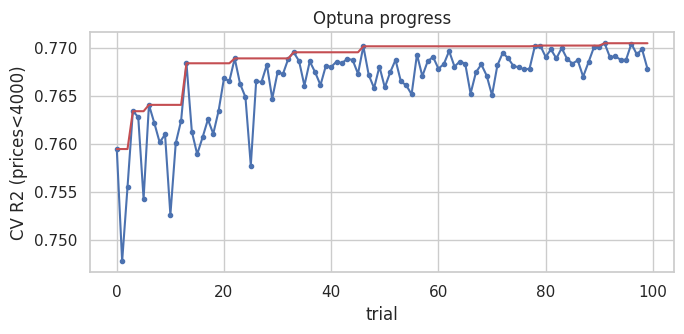

In [18]:
plt.figure(figsize=(7, 3.5))
vals = [t.value for t in study.trials]
plt.plot(vals, "o-", ms=3); plt.plot(np.maximum.accumulate(vals), "r-")
plt.xlabel("trial"); plt.ylabel("CV R2 (prices<4000)"); plt.title("Optuna progress"); plt.tight_layout(); plt.show()

In [19]:
def make_model(params, n_est, seed):
    p2 = {k: v for k, v in params.items() if k != "huber_slope"}
    kw = dict(objective="reg:pseudohubererror", huber_slope=params.get("huber_slope", HUBER_SLOPE)) if MODE == "huber" else {}
    return xgb.XGBRegressor(**p2, **kw, n_estimators=n_est, tree_method="hist", enable_categorical=True, random_state=seed, n_jobs=-1, verbosity=0)

def fit_predict(Xtr, ytr, Xte, params, seeds, n_est):
    preds = []
    for s in seeds:
        m = make_model(params, n_est, s).fit(Xtr[SELECTED], np.log1p(ytr) if MODE == "log" else ytr)
        p = m.predict(Xte[SELECTED]); preds.append(np.expm1(p) if MODE == "log" else p)
    return np.clip(np.mean(preds, axis=0), 0, None), m

dev_tr, (hold_te,) = te_fit_apply(dev_X, np.log1p(dev_y), [hold_X])
hold_pred, _ = fit_predict(dev_tr, dev_y, hold_te, BEST_PARAMS, [SEED], int(BEST_ROUNDS * 1.1))

# reference models trained the same way, for comparison
ref = {}
for mode_ in ["raw", "log"]:
    m_ = xgb.XGBRegressor(**BASE_PARAMS, n_estimators=res[mode_]["rounds"], tree_method="hist", enable_categorical=True, random_state=SEED, n_jobs=-1, verbosity=0)
    m_.fit(dev_tr[ID_FREE], np.log1p(dev_y) if mode_ == "log" else dev_y)
    p_ = m_.predict(hold_te[ID_FREE]); ref[mode_] = np.clip(np.expm1(p_) if mode_ == "log" else p_, 0, None)

def report(name, yt, yp):
    return {"model": name, "R2": r2_score(yt, yp), "RMSE": rmse(yt, yp), "MAE": mean_absolute_error(yt, yp)}
pd.DataFrame([report("naive mean", hold_y, np.full_like(hold_y, dev_y.mean())),
              report("XGB raw (default)", hold_y, ref["raw"]),
              report("XGB log (default)", hold_y, ref["log"]),
              report(f"XGB {MODE} tuned (final)", hold_y, hold_pred)]).round(4).set_index("model")

,R2,RMSE,MAE
model,,,
naive mean,-0.0003,197.7331,133.7631
XGB raw (default),0.7667,95.4987,46.9027
XGB log (default),0.8004,88.3236,40.2124
XGB huber tuned (final),0.8037,87.5913,40.5622


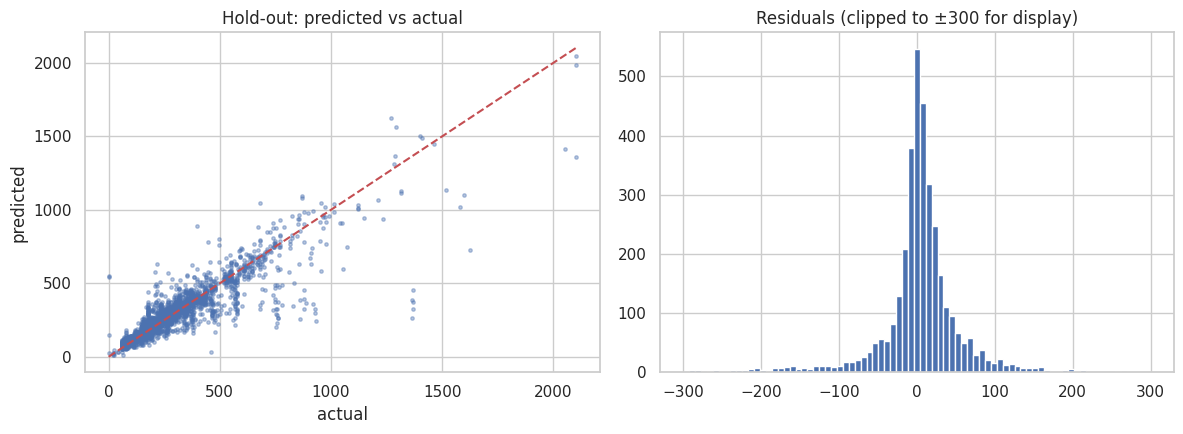

Share of total squared error from the 10 worst hold-out rows: 28%  -> this is why R2 moves so much between splits


In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(hold_y, hold_pred, s=6, alpha=.4); lim = [0, max(hold_y.max(), hold_pred.max())]
ax[0].plot(lim, lim, "r--"); ax[0].set_xlabel("actual"); ax[0].set_ylabel("predicted"); ax[0].set_title("Hold-out: predicted vs actual")
ax[1].hist(hold_pred - hold_y, bins=np.linspace(-300, 300, 80)); ax[1].set_title("Residuals (clipped to ±300 for display)")
plt.tight_layout(); plt.show()
sse = np.sort((hold_y - hold_pred) ** 2)[::-1]
print(f"Share of total squared error from the 10 worst hold-out rows: {sse[:10].sum()/sse.sum():.0%}  -> this is why R2 moves so much between splits")

In [ ]:
full_tr, (full_te,) = te_fit_apply(F_train, np.log1p(y), [F_test])
final_n_est = int(BEST_ROUNDS * 1.25)     # ~25 % more data than the CV folds -> a few more rounds
test_pred, last_model = fit_predict(full_tr, y, full_te, [SEED + i for i in range(N_FINAL_SEEDS)], final_n_est)

sub = pd.DataFrame({"id": test["id"].values, "price": np.round(test_pred, 2)})
sub = sample_sub[["id"]].merge(sub, on="id", how="left")          # same id order as the sample file
sub.to_csv("submission_xg_boost_tuned.csv", index=False)
print("Saved submission_random_forest.csv")
print("Submission shape:", sub.shape)
print(sub.head())
print("Predicted price range:", round(sub.price.min(), 2), "to", round(sub.price.max(), 2))
assert len(sub) == len(test)
assert sub["price"].notna().all()
assert sub["id"].equals(test["id"])
assert list(sub.columns) == ["id", "price"]